# 01 · Association rules: tag pattern miner

**DMDW topics:** frequent itemsets, Apriori vs FP-Growth, support / confidence / lift, constraint-based mining.

Transaction = the set of tags of the problems one user solved.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display

from cfiq.config import load_config
from cfiq.db import get_engine, read_sql

cfg = load_config()
engine = get_engine()
REPORTS = cfg["paths"]["reports"]
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
from cfiq.mining import association as A
acfg = cfg['mining']['association']; acfg

{'drop_items_above_support': 0.95,
 'min_support': 0.4,
 'min_confidence': 0.8,
 'min_lift': 1.1,
 'max_len': 3,
 'runtime_supports': [0.6, 0.5, 0.4, 0.3],
 'basket_runtime_supports': [0.1, 0.05, 0.03, 0.02, 0.01],
 'runtime_repeats': 3,
 'constraint_band': 'GM',
 'constraint_category': 'graph theory'}

In [2]:
solved = read_sql(engine, A.SOLVED_TAGS_SQL)
tx = A.to_transactions(solved)
onehot = A.one_hot(tx)
print(len(tx), 'transactions; first one:', tx[0][:10])
onehot.head()

346 transactions; first one: ['2-sat', 'binary search', 'bitmasks', 'brute force', 'chinese remainder theorem', 'combinatorics', 'communication', 'constructive algorithms', 'data structures', 'dfs and similar']


,*broken,*special,2-sat,binary search,bitmasks,brute force,chinese remainder theorem,combinatorics,communication,constructive algorithms,data structures,dfs and similar,divide and conquer,dp,dsu,...,implementation,interactive,math,matrices,meet-in-the-middle,number theory,probabilities,schedules,shortest paths,sortings,string suffix structures,strings,ternary search,trees,two pointers
0,False,False,True,True,True,True,True,True,True,True,True,True,True,True,True,...,True,True,True,False,False,True,False,True,True,True,False,True,False,True,True
1,False,False,False,True,True,True,True,False,False,True,True,False,False,True,True,...,True,True,True,False,False,True,False,False,False,True,False,True,False,False,True
2,False,True,True,True,True,True,False,True,False,True,True,True,True,True,True,...,True,True,True,True,False,True,True,True,True,True,True,True,False,True,True
3,False,False,False,True,True,True,False,True,False,True,True,True,False,True,True,...,True,True,True,False,False,True,False,False,False,True,False,True,False,True,True
4,False,False,True,True,True,True,False,True,False,True,True,False,False,True,True,...,True,True,True,False,False,True,False,False,False,True,False,True,False,False,True


## Apriori vs FP-Growth at the same min_support

In [3]:
rt = A.compare_runtimes(onehot, acfg['runtime_supports'], acfg['runtime_repeats'], acfg['max_len'])
rt

,min_support,itemsets,apriori_s,fpgrowth_s,apriori_over_fpgrowth
0,0.6,1392,0.007006,0.025761,0.271979
1,0.5,1723,0.007053,0.039440,0.178822
2,0.4,2332,0.008566,0.050949,0.168132
3,0.3,3992,0.015821,0.074910,0.211199


## Rules (FP-Growth itemsets → confidence/lift filter)

In [4]:
itemsets, rules = A.mine_rules(onehot, acfg['min_support'], acfg['min_confidence'], acfg['min_lift'], acfg['max_len'])
print(len(itemsets), 'frequent itemsets,', len(rules), 'rules')
A.format_rules(rules, 'all').head(15)

2332 frequent itemsets, 2763 rules


,rule_set,antecedents,consequents,support,confidence,lift
0,all,divide and conquer,"geometry, trees",0.4393,0.8352,1.5050
1,all,divide and conquer,"dsu, interactive",0.4364,0.8297,1.4951
2,all,hashing,"combinatorics, geometry",0.4046,0.8696,1.4749
3,all,divide and conquer,"dsu, trees",0.4798,0.9121,1.4747
4,all,divide and conquer,"combinatorics, interactive",0.4480,0.8516,1.4734
5,all,hashing,"dfs and similar, geometry",0.4162,0.8944,1.4667
6,all,divide and conquer,"interactive, trees",0.4538,0.8626,1.4631
7,all,divide and conquer,"combinatorics, dsu",0.4798,0.9121,1.4610
8,all,hashing,"geometry, graphs",0.4017,0.8634,1.4572
9,all,divide and conquer,"combinatorics, trees",0.4971,0.9451,1.4469


## Constraint-based mining
Run the full module (also writes the constrained rule sets, plots and the `mine_assoc_rules` table).

In [5]:
A.run_association(cfg, engine)
text = (REPORTS / 'association' / 'summary.md').read_text()
display(Markdown(text[text.index('## Constraint'):]))

## Constraint: band = GM only (50 users, 830 rules)

| antecedents | consequents | support | confidence | lift |
|---|---|---|---|---|
| communication, flows | expression parsing | 0.420 | 0.875 | 1.367 |
| chinese remainder theorem, communication | expression parsing | 0.420 | 0.875 | 1.367 |
| communication | expression parsing, flows | 0.420 | 0.808 | 1.346 |
| communication | chinese remainder theorem, expression parsing | 0.420 | 0.808 | 1.346 |
| meet-in-the-middle | schedules, ternary search | 0.420 | 0.913 | 1.343 |
| meet-in-the-middle | chinese remainder theorem, schedules | 0.420 | 0.913 | 1.343 |
| meet-in-the-middle | flows, schedules | 0.440 | 0.957 | 1.329 |
| schedules, string suffix structures | *special | 0.560 | 0.903 | 1.328 |
| *special | schedules, string suffix structures | 0.560 | 0.824 | 1.328 |
| expression parsing, schedules | *special | 0.500 | 0.893 | 1.313 |

## Constraint: all items in category 'graph theory' (pushed into mining, 18 rules)

| antecedents | consequents | support | confidence | lift |
|---|---|---|---|---|
| shortest paths | dfs and similar, graphs | 0.402 | 0.972 | 1.329 |
| dfs and similar, shortest paths | graphs | 0.402 | 0.993 | 1.282 |
| dfs and similar, graphs | trees | 0.679 | 0.929 | 1.270 |
| trees | dfs and similar, graphs | 0.679 | 0.929 | 1.270 |
| shortest paths | graphs | 0.405 | 0.979 | 1.264 |
| graph matchings | graphs | 0.402 | 0.959 | 1.238 |
| graphs, shortest paths | dfs and similar | 0.402 | 0.993 | 1.227 |
| graphs, trees | dfs and similar | 0.679 | 0.992 | 1.225 |
| dfs and similar | graphs, trees | 0.679 | 0.839 | 1.225 |
| dfs and similar | trees | 0.723 | 0.893 | 1.221 |


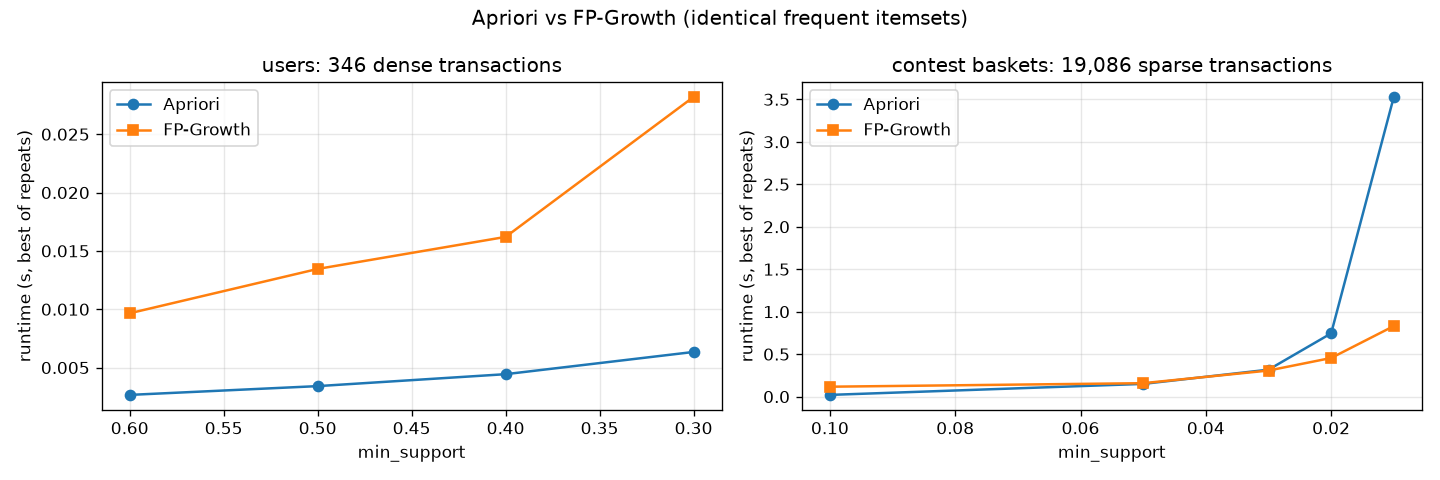

In [6]:
Image(REPORTS / 'association' / 'runtime_comparison.png')